In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style="whitegrid")

print("EDA libraries imported successfully!")

EDA libraries imported successfully!


In [11]:
PROJECT_DIR = Path.cwd().parent
DATA_DIR = PROJECT_DIR / "data" / "raw"

print("Project Directory:", PROJECT_DIR)
print("Data Directory:", DATA_DIR)

Project Directory: c:\Users\hp\OneDrive\Desktop\WasteWise AI
Data Directory: c:\Users\hp\OneDrive\Desktop\WasteWise AI\data\raw


In [12]:
print("Project folder exists:", PROJECT_DIR.exists())
print("Data folder exists:", DATA_DIR.exists())

Project folder exists: True
Data folder exists: True


In [13]:
products_df = pd.read_csv(DATA_DIR / "products.csv")
perishable_df = pd.read_csv(DATA_DIR / "perishable_inventory.csv")
batches_df = pd.read_csv(DATA_DIR / "inventory_batches.csv")
discount_df = pd.read_csv(DATA_DIR / "discount_scenarios_simulated.csv")
calendar_df = pd.read_csv(DATA_DIR / "calendar.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


expiry_risk_label
0     828
1    1172
Name: count, dtype: int64


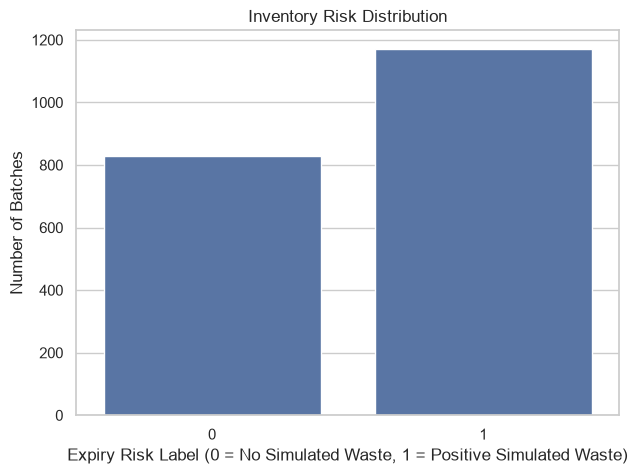

In [14]:
risk_counts = (
    batches_df["expiry_risk_label"]
    .value_counts()
    .sort_index()
)

print(risk_counts)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=risk_counts.index.astype(str),
    y=risk_counts.values
)

plt.title("Inventory Risk Distribution")
plt.xlabel("Expiry Risk Label (0 = No Simulated Waste, 1 = Positive Simulated Waste)")
plt.ylabel("Number of Batches")

plt.show()

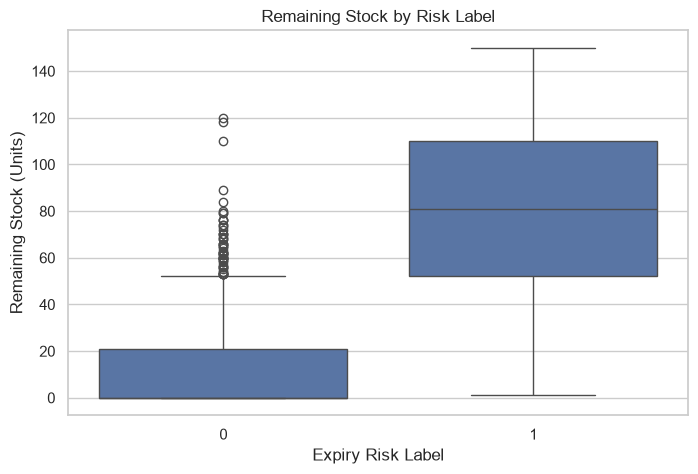

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=batches_df,
    x="expiry_risk_label",
    y="quantity_remaining"
)

plt.title("Remaining Stock by Risk Label")
plt.xlabel("Expiry Risk Label")
plt.ylabel("Remaining Stock (Units)")

plt.show()

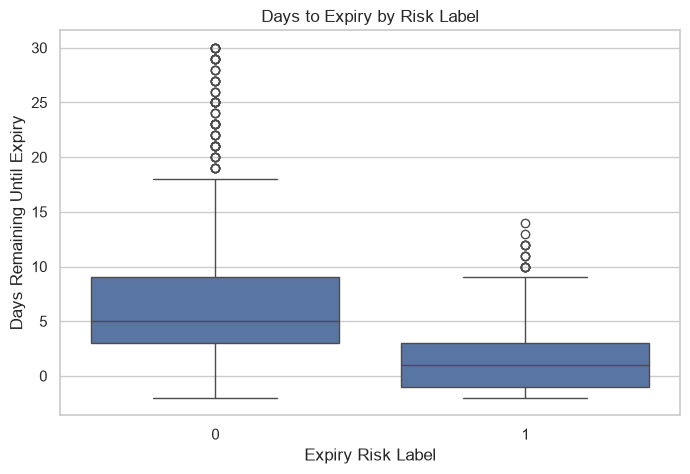

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=batches_df,
    x="expiry_risk_label",
    y="days_to_expiry"
)

plt.title("Days to Expiry by Risk Label")
plt.xlabel("Expiry Risk Label")
plt.ylabel("Days Remaining Until Expiry")

plt.show()

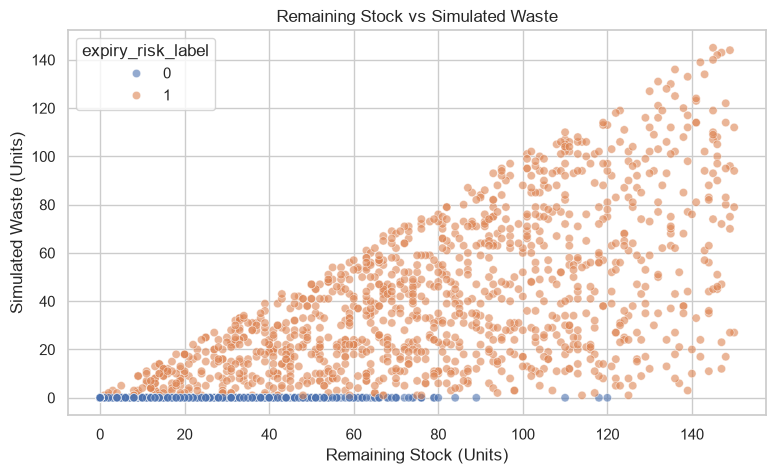

In [17]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=batches_df,
    x="quantity_remaining",
    y="waste_units_actual_simulated",
    hue="expiry_risk_label",
    alpha=0.6
)

plt.title("Remaining Stock vs Simulated Waste")
plt.xlabel("Remaining Stock (Units)")
plt.ylabel("Simulated Waste (Units)")

plt.show()

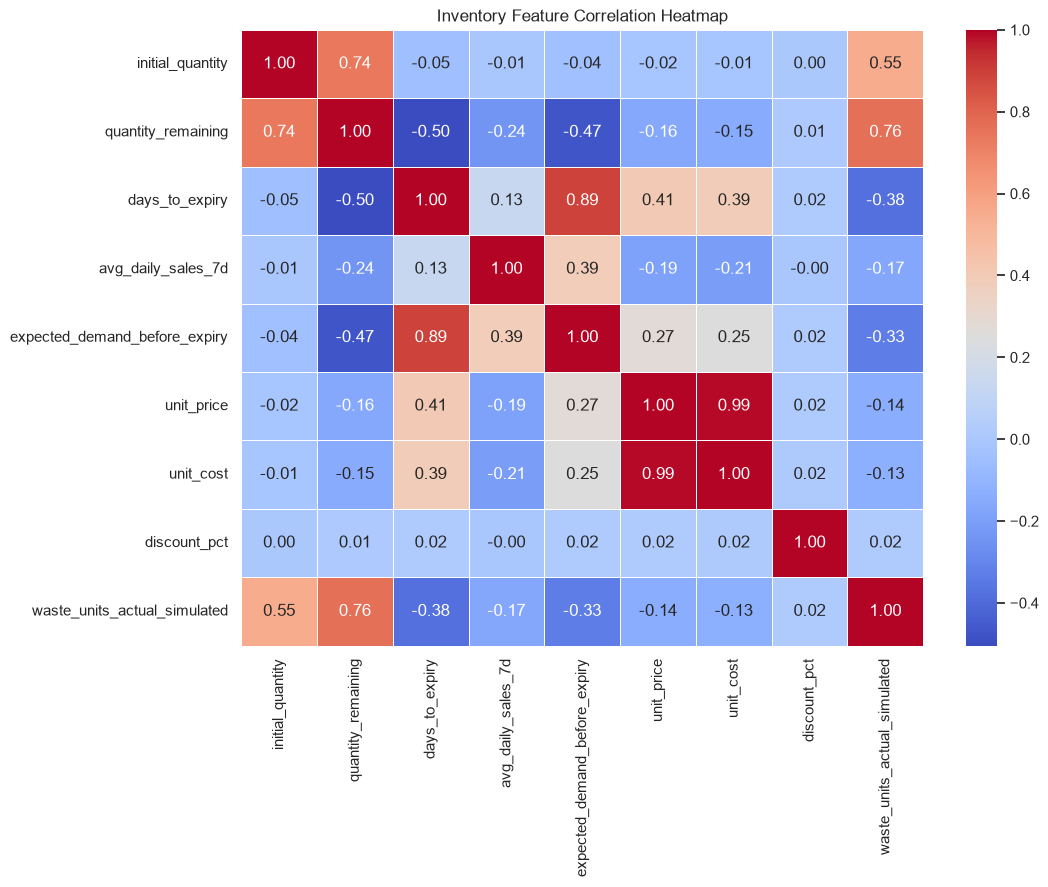

In [18]:
numeric_columns = [
    "initial_quantity",
    "quantity_remaining",
    "days_to_expiry",
    "avg_daily_sales_7d",
    "expected_demand_before_expiry",
    "unit_price",
    "unit_cost",
    "discount_pct",
    "waste_units_actual_simulated"
]

correlation_matrix = batches_df[numeric_columns].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Inventory Feature Correlation Heatmap")

plt.show()

In [19]:
product_analysis = batches_df.groupby("product_id").agg(
    total_batches=("batch_id", "count"),
    total_remaining_stock=("quantity_remaining", "sum"),
    total_simulated_waste=("waste_units_actual_simulated", "sum"),
    average_days_to_expiry=("days_to_expiry", "mean"),
    high_risk_batches=("expiry_risk_label", "sum")
).reset_index()

display(product_analysis)

,product_id,total_batches,total_remaining_stock,total_simulated_waste,average_days_to_expiry,high_risk_batches
0,1001,218,15909,7571,1.646789,165
1,1002,195,7306,3816,4.066667,80
2,1003,196,12072,5476,0.882653,145
3,1004,178,9404,4019,2.556180,104
4,1005,209,14565,6732,0.612440,159
5,1006,200,8267,3583,2.575000,97
6,1007,199,9728,4016,6.025126,112
7,1008,203,3372,1491,13.192118,33
8,1009,199,11818,6033,2.959799,138
9,1010,203,13115,6252,1.428571,139


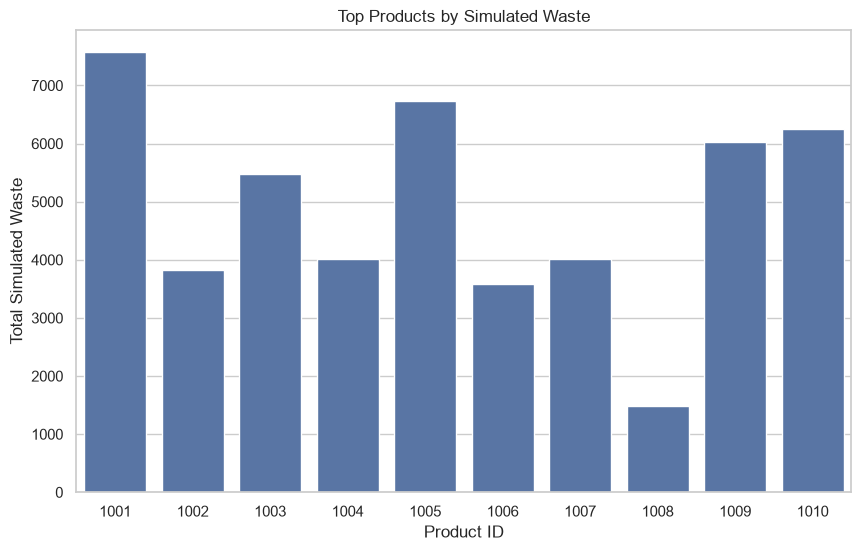

In [20]:
top_products = product_analysis.sort_values(
    by="total_simulated_waste",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_products,
    x="product_id",
    y="total_simulated_waste"
)

plt.title("Top Products by Simulated Waste")
plt.xlabel("Product ID")
plt.ylabel("Total Simulated Waste")

plt.show()

In [21]:
product_analysis_named = product_analysis.merge(
    products_df[
        ["product_id", "product_name", "category", "shelf_life_days"]
    ],
    on="product_id",
    how="left"
)

display(
    product_analysis_named.sort_values(
        "total_simulated_waste",
        ascending=False
    )
)

,product_id,total_batches,total_remaining_stock,total_simulated_waste,average_days_to_expiry,high_risk_batches,product_name,category,shelf_life_days
0,1001,218,15909,7571,1.646789,165,Milk 500ml,Dairy,5
4,1005,209,14565,6732,0.612440,159,Spinach Pack,Produce,3
9,1010,203,13115,6252,1.428571,139,Muffin Pack,Bakery,5
8,1009,199,11818,6033,2.959799,138,Fresh Cream,Dairy,8
2,1003,196,12072,5476,0.882653,145,Bread Loaf,Bakery,4
3,1004,178,9404,4019,2.556180,104,Paneer 200g,Dairy,7
6,1007,199,9728,4016,6.025126,112,Apple 1kg,Produce,14
1,1002,195,7306,3816,4.066667,80,Yogurt Cup,Dairy,10
5,1006,200,8267,3583,2.575000,97,Tomatoes 1kg,Produce,7
7,1008,203,3372,1491,13.192118,33,Orange Juice 1L,Beverage,30


In [22]:
initial_stock_by_product = (
    batches_df.groupby("product_id")["initial_quantity"]
    .sum()
    .reset_index(name="total_initial_stock")
)

product_analysis_named = product_analysis_named.merge(
    initial_stock_by_product,
    on="product_id",
    how="left"
)

product_analysis_named["waste_per_batch"] = (
    product_analysis_named["total_simulated_waste"] /
    product_analysis_named["total_batches"]
)

product_analysis_named["waste_percentage"] = (
    product_analysis_named["total_simulated_waste"] /
    product_analysis_named["total_initial_stock"]
) * 100

display(
    product_analysis_named[
        [
            "product_name",
            "category",
            "total_batches",
            "total_simulated_waste",
            "waste_per_batch",
            "waste_percentage"
        ]
    ].round(2).sort_values(
        "waste_percentage",
        ascending=False
    )
)

,product_name,category,total_batches,total_simulated_waste,waste_per_batch,waste_percentage
0,Milk 500ml,Dairy,218,7571,34.73,40.81
9,Muffin Pack,Bakery,203,6252,30.80,40.33
4,Spinach Pack,Produce,209,6732,32.21,39.71
8,Fresh Cream,Dairy,199,6033,30.32,36.74
2,Bread Loaf,Bakery,196,5476,27.94,34.34
3,Paneer 200g,Dairy,178,4019,22.58,27.54
6,Apple 1kg,Produce,199,4016,20.18,24.55
1,Yogurt Cup,Dairy,195,3816,19.57,23.24
5,Tomatoes 1kg,Produce,200,3583,17.92,22.93
7,Orange Juice 1L,Beverage,203,1491,7.34,9.45


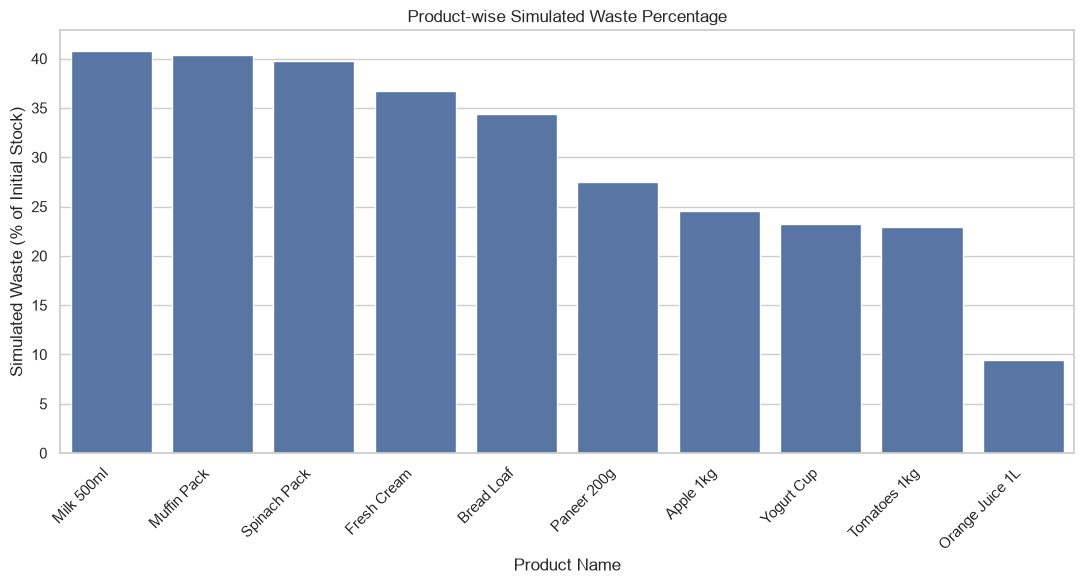

In [23]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=product_analysis_named.sort_values(
        "waste_percentage",
        ascending=False
    ),
    x="product_name",
    y="waste_percentage"
)

plt.title("Product-wise Simulated Waste Percentage")
plt.xlabel("Product Name")
plt.ylabel("Simulated Waste (% of Initial Stock)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [24]:
perishable_analysis = perishable_df.groupby("category").agg(
    total_records=("product_id", "count"),
    total_opening_stock=("opening_stock", "sum"),
    total_units_received=("units_received", "sum"),
    total_units_sold=("units_sold", "sum"),
    total_waste=("waste_units", "sum"),
    average_days_to_expiry=("days_to_expiry", "mean"),
    stockout_count=("stockout_flag", "sum")
).reset_index()

display(perishable_analysis)

,category,total_records,total_opening_stock,total_units_received,total_units_sold,total_waste,average_days_to_expiry,stockout_count
0,Bakery,360,11941,805,6585,459,2.286111,27
1,Beverage,180,7865,505,5015,277,15.477778,11
2,Dairy,720,24281,1696,13239,1056,3.773611,50
3,Produce,540,19554,1357,11428,810,3.838889,48


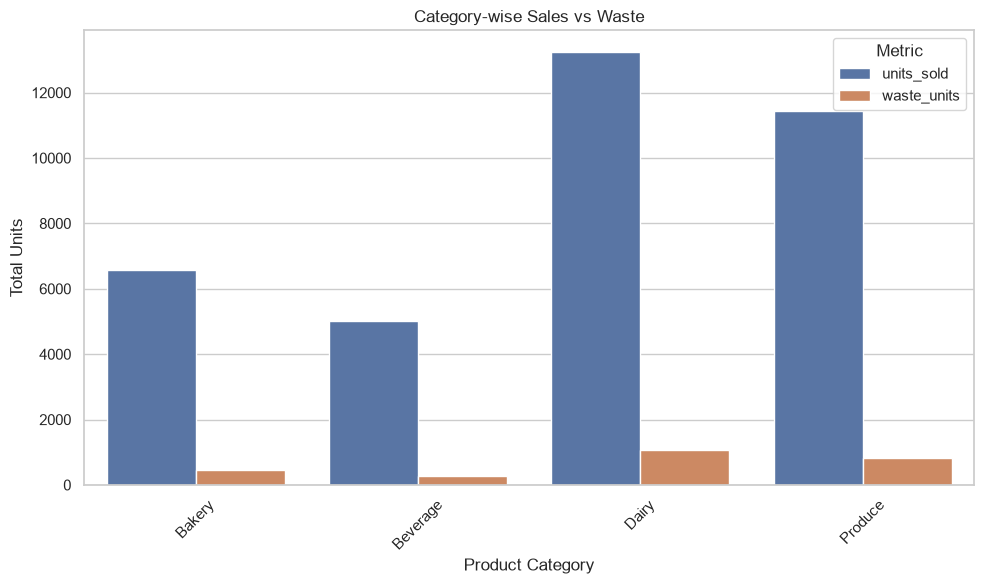

In [25]:
category_sales_waste = perishable_df.groupby("category")[
    ["units_sold", "waste_units"]
].sum().reset_index()

category_sales_waste = category_sales_waste.melt(
    id_vars="category",
    var_name="Metric",
    value_name="Units"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_sales_waste,
    x="category",
    y="Units",
    hue="Metric"
)

plt.title("Category-wise Sales vs Waste")
plt.xlabel("Product Category")
plt.ylabel("Total Units")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
stockout_analysis = perishable_df.groupby("category").agg(
    total_records=("stockout_flag", "count"),
    stockout_cases=("stockout_flag", "sum")
).reset_index()

stockout_analysis["stockout_percentage"] = (
    stockout_analysis["stockout_cases"] /
    stockout_analysis["total_records"]
) * 100

display(stockout_analysis)

,category,total_records,stockout_cases,stockout_percentage
0,Bakery,360,27,7.500000
1,Beverage,180,11,6.111111
2,Dairy,720,50,6.944444
3,Produce,540,48,8.888889


In [27]:
print("Dataset Shape:", discount_df.shape)

display(discount_df.head())

print("\nColumn Information:")
discount_df.info()

Dataset Shape: (10000, 8)


,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
0,5001,1006,5,72,0,72,3240.0,1224.0
1,5001,1006,5,72,5,72,3078.0,1062.0
2,5001,1006,5,72,10,72,2916.0,900.0
3,5001,1006,5,72,15,72,2754.0,738.0
4,5001,1006,5,72,20,72,2592.0,576.0



Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   batch_id                          10000 non-null  int64  
 1   product_id                        10000 non-null  int64  
 2   days_to_expiry                    10000 non-null  int64  
 3   quantity_remaining                10000 non-null  int64  
 4   discount_pct                      10000 non-null  int64  
 5   estimated_units_sold_simulated    10000 non-null  int64  
 6   estimated_revenue_simulated       10000 non-null  float64
 7   estimated_gross_margin_simulated  10000 non-null  float64
dtypes: float64(2), int64(6)
memory usage: 625.1 KB


In [28]:
discount_analysis = discount_df.groupby("discount_pct").agg(
    total_scenarios=("batch_id", "count"),
    total_estimated_units_sold=(
        "estimated_units_sold_simulated", "sum"
    ),
    total_estimated_revenue=(
        "estimated_revenue_simulated", "sum"
    ),
    total_estimated_gross_margin=(
        "estimated_gross_margin_simulated", "sum"
    )
).reset_index()

display(discount_analysis)

,discount_pct,total_scenarios,total_estimated_units_sold,total_estimated_revenue,total_estimated_gross_margin
0,0,2000,29026,1787809.00,595539.00
1,5,2000,31040,1804770.10,537541.10
2,10,2000,32907,1802186.10,466279.10
3,15,2000,34613,1781434.25,383084.25
4,20,2000,36121,1743169.60,289246.60


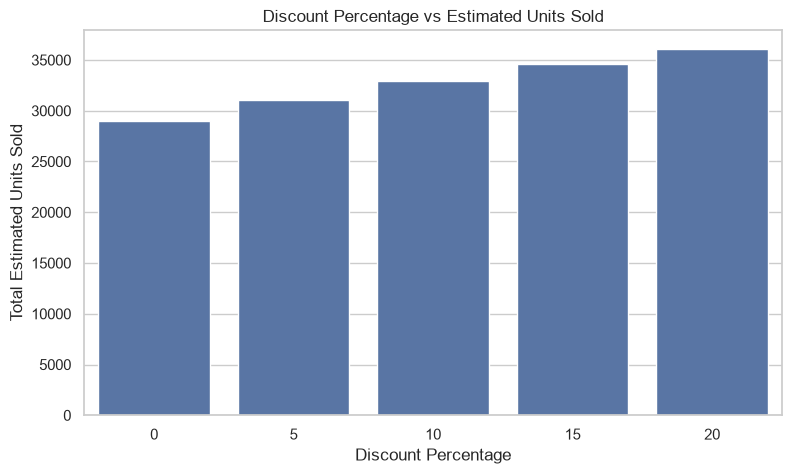

In [29]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_analysis,
    x="discount_pct",
    y="total_estimated_units_sold"
)

plt.title("Discount Percentage vs Estimated Units Sold")
plt.xlabel("Discount Percentage")
plt.ylabel("Total Estimated Units Sold")

plt.show()

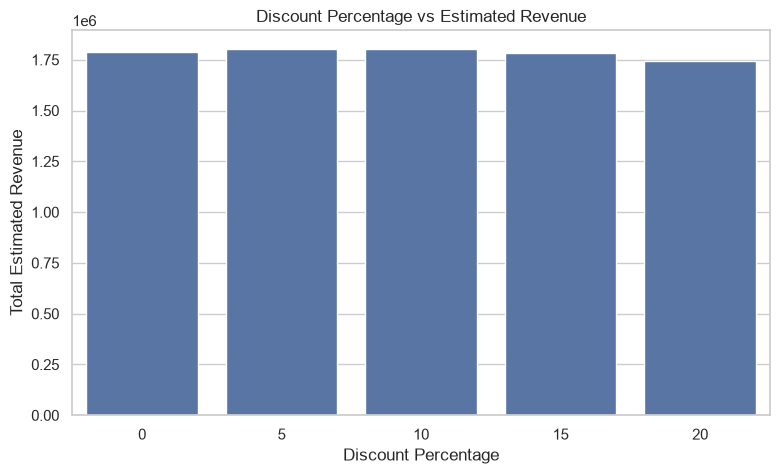

In [30]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_analysis,
    x="discount_pct",
    y="total_estimated_revenue"
)

plt.title("Discount Percentage vs Estimated Revenue")
plt.xlabel("Discount Percentage")
plt.ylabel("Total Estimated Revenue")

plt.show()

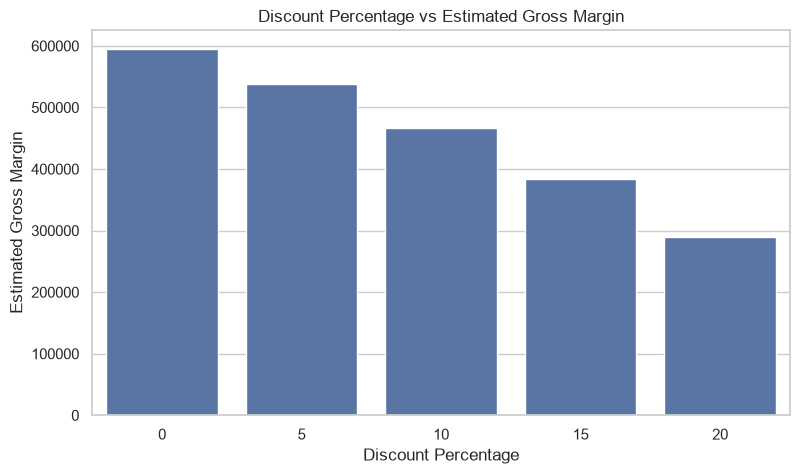

In [31]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=discount_analysis,
    x="discount_pct",
    y="total_estimated_gross_margin"
)

plt.title("Discount Percentage vs Estimated Gross Margin")
plt.xlabel("Discount Percentage")
plt.ylabel("Estimated Gross Margin")

plt.show()

In [32]:
best_discount = discount_analysis.loc[
    discount_analysis["total_estimated_gross_margin"].idxmax()
]

print("Best discount based on total estimated gross margin:")

display(best_discount)

Best discount based on total estimated gross margin:


discount_pct                          0.0
total_scenarios                    2000.0
total_estimated_units_sold        29026.0
total_estimated_revenue         1787809.0
total_estimated_gross_margin     595539.0
Name: 0, dtype: float64

In [33]:
# Get the 0% discount scenario for every batch
baseline = discount_df[
    discount_df["discount_pct"] == 0
][
    ["batch_id", "estimated_units_sold_simulated",
     "estimated_revenue_simulated",
     "estimated_gross_margin_simulated"]
].copy()

baseline = baseline.rename(columns={
    "estimated_units_sold_simulated": "baseline_units",
    "estimated_revenue_simulated": "baseline_revenue",
    "estimated_gross_margin_simulated": "baseline_margin"
})

# Compare all scenarios with the baseline
discount_comparison = discount_df.merge(
    baseline,
    on="batch_id",
    how="left"
)

discount_comparison["additional_units"] = (
    discount_comparison["estimated_units_sold_simulated"] -
    discount_comparison["baseline_units"]
)

discount_comparison["margin_change"] = (
    discount_comparison["estimated_gross_margin_simulated"] -
    discount_comparison["baseline_margin"]
)

display(
    discount_comparison.groupby("discount_pct").agg(
        additional_units=("additional_units", "sum"),
        margin_change=("margin_change", "sum")
    ).reset_index()
)

,discount_pct,additional_units,margin_change
0,0,0,0.00
1,5,2014,-57997.90
2,10,3881,-129259.90
3,15,5587,-212454.75
4,20,7095,-306292.40


In [34]:
# Only consider non-expired batches with stock available
eligible_scenarios = discount_df[
    (discount_df["days_to_expiry"] >= 0) &
    (discount_df["quantity_remaining"] > 0)
].copy()

# Sort by highest margin, then lowest discount
eligible_scenarios = eligible_scenarios.sort_values(
    by=[
        "estimated_gross_margin_simulated",
        "discount_pct"
    ],
    ascending=[False, True]
)

# Select the best margin scenario for each batch
best_batch_discount = eligible_scenarios.drop_duplicates(
    subset="batch_id",
    keep="first"
)

display(
    best_batch_discount[
        [
            "batch_id",
            "product_id",
            "days_to_expiry",
            "quantity_remaining",
            "discount_pct",
            "estimated_units_sold_simulated",
            "estimated_revenue_simulated",
            "estimated_gross_margin_simulated"
        ]
    ].head(20)
)

print("Eligible batches:", eligible_scenarios["batch_id"].nunique())
print("Batches with selected scenarios:", len(best_batch_discount))

,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated
9640,6929,1007,7,87,0,87,10440.0,3654.0
3190,5639,1007,9,83,0,83,9960.0,3486.0
8205,6642,1007,9,82,0,82,9840.0,3444.0
8540,6709,1007,8,81,0,81,9720.0,3402.0
2650,5531,1007,6,79,0,79,9480.0,3318.0
6255,6252,1007,9,79,0,79,9480.0,3318.0
5670,6135,1007,10,77,0,77,9240.0,3234.0
9220,6845,1007,6,76,0,76,9120.0,3192.0
5445,6090,1007,12,75,0,75,9000.0,3150.0
1230,5247,1007,12,73,0,73,8760.0,3066.0


Eligible batches: 1134
Batches with selected scenarios: 1134


discount_pct
0     1111
5       22
10       1
Name: count, dtype: int64


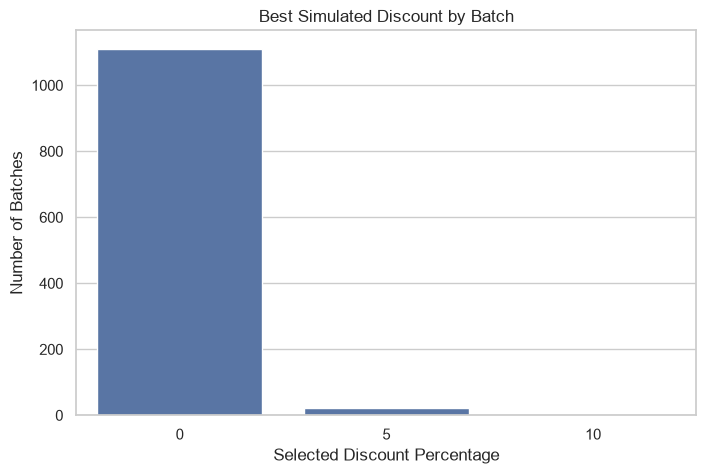

In [35]:
best_discount_counts = (
    best_batch_discount["discount_pct"]
    .value_counts()
    .sort_index()
)

print(best_discount_counts)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=best_discount_counts.index.astype(str),
    y=best_discount_counts.values
)

plt.title("Best Simulated Discount by Batch")
plt.xlabel("Selected Discount Percentage")
plt.ylabel("Number of Batches")

plt.show()

In [36]:
REPORT_DIR = PROJECT_DIR / "reports"
REPORT_DIR.mkdir(exist_ok=True)

discount_analysis.to_csv(
    REPORT_DIR / "discount_performance_summary.csv",
    index=False
)

best_batch_discount.to_csv(
    REPORT_DIR / "best_batch_discount_simulated.csv",
    index=False
)

print("Discount analysis reports saved successfully!")

Discount analysis reports saved successfully!


In [37]:
batch_context = batches_df[
    [
        "batch_id",
        "snapshot_date",
        "expiry_date",
        "avg_daily_sales_7d",
        "expected_demand_before_expiry"
    ]
].copy()

scenario_analysis = discount_df.merge(
    batch_context,
    on="batch_id",
    how="left",
    validate="many_to_one"
)

scenario_analysis["inventory_surplus"] = (
    scenario_analysis["quantity_remaining"] -
    scenario_analysis["expected_demand_before_expiry"]
)

print("Scenario rows:", len(scenario_analysis))
print("Missing batch information:",
      scenario_analysis["expected_demand_before_expiry"].isna().sum())

display(scenario_analysis.head())

Scenario rows: 10000
Missing batch information: 0


,batch_id,product_id,days_to_expiry,quantity_remaining,discount_pct,estimated_units_sold_simulated,estimated_revenue_simulated,estimated_gross_margin_simulated,snapshot_date,expiry_date,avg_daily_sales_7d,expected_demand_before_expiry,inventory_surplus
0,5001,1006,5,72,0,72,3240.0,1224.0,2026-08-16,2026-08-21,23.38,117,-45
1,5001,1006,5,72,5,72,3078.0,1062.0,2026-08-16,2026-08-21,23.38,117,-45
2,5001,1006,5,72,10,72,2916.0,900.0,2026-08-16,2026-08-21,23.38,117,-45
3,5001,1006,5,72,15,72,2754.0,738.0,2026-08-16,2026-08-21,23.38,117,-45
4,5001,1006,5,72,20,72,2592.0,576.0,2026-08-16,2026-08-21,23.38,117,-45


In [38]:
at_risk_batches = scenario_analysis[
    (scenario_analysis["days_to_expiry"] >= 0) &
    (scenario_analysis["days_to_expiry"] <= 3) &
    (scenario_analysis["quantity_remaining"] > 0) &
    (scenario_analysis["inventory_surplus"] > 0)
].copy()

print(
    "Unique batches needing attention:",
    at_risk_batches["batch_id"].nunique()
)

print(
    "Total scenario records:",
    len(at_risk_batches)
)

display(
    at_risk_batches[
        [
            "batch_id",
            "product_id",
            "days_to_expiry",
            "quantity_remaining",
            "expected_demand_before_expiry",
            "inventory_surplus",
            "discount_pct",
            "estimated_units_sold_simulated",
            "estimated_gross_margin_simulated"
        ]
    ].head(15)
)

Unique batches needing attention: 616
Total scenario records: 3080


,batch_id,product_id,days_to_expiry,quantity_remaining,expected_demand_before_expiry,inventory_surplus,discount_pct,estimated_units_sold_simulated,estimated_gross_margin_simulated
5,5002,1006,1,123,37,86,0,37,629.00
6,5002,1006,1,123,37,86,5,41,604.75
7,5002,1006,1,123,37,86,10,46,575.00
8,5002,1006,1,123,37,86,15,51,522.75
9,5002,1006,1,123,37,86,20,55,440.00
30,5007,1010,1,73,9,64,0,9,189.00
31,5007,1010,1,73,9,64,5,11,200.75
32,5007,1010,1,73,9,64,10,12,186.00
33,5007,1010,1,73,9,64,15,13,165.75
34,5007,1010,1,73,9,64,20,14,140.00


In [39]:
risk_discount_analysis = at_risk_batches.groupby(
    "discount_pct"
).agg(
    total_batches=("batch_id", "nunique"),
    estimated_units_sold=(
        "estimated_units_sold_simulated", "sum"
    ),
    estimated_revenue=(
        "estimated_revenue_simulated", "sum"
    ),
    estimated_gross_margin=(
        "estimated_gross_margin_simulated", "sum"
    )
).reset_index()

display(risk_discount_analysis)

,discount_pct,total_batches,estimated_units_sold,estimated_revenue,estimated_gross_margin
0,0,616,11506,565639.00,187282.00
1,5,616,12900,602340.85,178259.85
2,10,616,14228,629442.00,161725.00
3,15,616,15461,645803.65,137769.65
4,20,616,16572,651794.40,107065.40


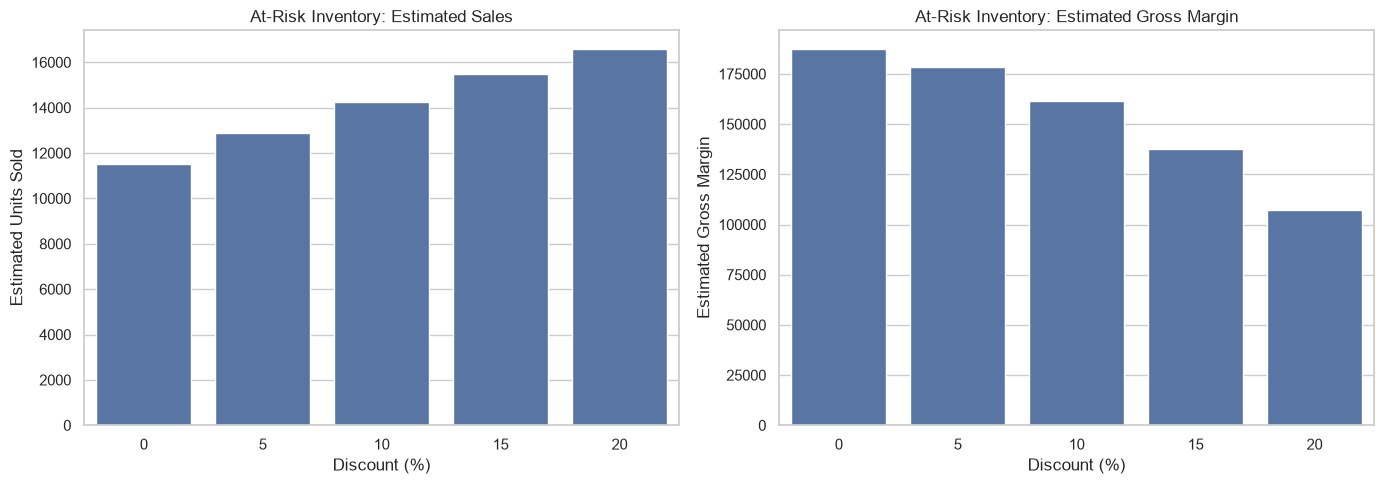

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=risk_discount_analysis,
    x="discount_pct",
    y="estimated_units_sold",
    ax=axes[0]
)

axes[0].set_title("At-Risk Inventory: Estimated Sales")
axes[0].set_xlabel("Discount (%)")
axes[0].set_ylabel("Estimated Units Sold")

sns.barplot(
    data=risk_discount_analysis,
    x="discount_pct",
    y="estimated_gross_margin",
    ax=axes[1]
)

axes[1].set_title("At-Risk Inventory: Estimated Gross Margin")
axes[1].set_xlabel("Discount (%)")
axes[1].set_ylabel("Estimated Gross Margin")

plt.tight_layout()
plt.show()

In [41]:
baseline = at_risk_batches[
    at_risk_batches["discount_pct"] == 0
][
    [
        "batch_id",
        "estimated_units_sold_simulated",
        "estimated_gross_margin_simulated"
    ]
].rename(columns={
    "estimated_units_sold_simulated": "baseline_units",
    "estimated_gross_margin_simulated": "baseline_margin"
})

batch_comparison = at_risk_batches.merge(
    baseline,
    on="batch_id",
    how="left",
    validate="many_to_one"
)

batch_comparison["additional_units"] = (
    batch_comparison["estimated_units_sold_simulated"]
    - batch_comparison["baseline_units"]
)

batch_comparison["margin_lost"] = (
    batch_comparison["baseline_margin"]
    - batch_comparison["estimated_gross_margin_simulated"]
)

batch_comparison["margin_lost_per_extra_unit"] = np.where(
    batch_comparison["additional_units"] > 0,
    batch_comparison["margin_lost"] /
    batch_comparison["additional_units"],
    np.nan
)

batch_comparison["remaining_after_estimated_sales"] = (
    batch_comparison["quantity_remaining"]
    - batch_comparison["estimated_units_sold_simulated"]
)

display(
    batch_comparison[
        [
            "batch_id",
            "days_to_expiry",
            "quantity_remaining",
            "discount_pct",
            "additional_units",
            "margin_lost",
            "margin_lost_per_extra_unit",
            "remaining_after_estimated_sales"
        ]
    ].head(20)
)

,batch_id,days_to_expiry,quantity_remaining,discount_pct,additional_units,margin_lost,margin_lost_per_extra_unit,remaining_after_estimated_sales
0,5002,1,123,0,0,0.00,NaN,86
1,5002,1,123,5,4,24.25,6.062500,82
2,5002,1,123,10,9,54.00,6.000000,77
3,5002,1,123,15,14,106.25,7.589286,72
4,5002,1,123,20,18,189.00,10.500000,68
5,5007,1,73,0,0,0.00,NaN,64
6,5007,1,73,5,2,-11.75,-5.875000,62
7,5007,1,73,10,3,3.00,1.000000,61
8,5007,1,73,15,4,23.25,5.812500,60
9,5007,1,73,20,5,49.00,9.800000,59


In [42]:
batch_discount_summary = batch_comparison.groupby(
    "discount_pct"
).agg(
    total_batches=("batch_id", "nunique"),
    additional_units=("additional_units", "sum"),
    total_margin_lost=("margin_lost", "sum"),
    average_margin_lost_per_extra_unit=(
        "margin_lost_per_extra_unit", "mean"
    ),
    average_remaining_stock=(
        "remaining_after_estimated_sales", "mean"
    )
).reset_index()

display(batch_discount_summary.round(2))

,discount_pct,total_batches,additional_units,total_margin_lost,average_margin_lost_per_extra_unit,average_remaining_stock
0,0,616,0,0.00,NaN,62.91
1,5,616,1394,9022.15,7.72,60.65
2,10,616,2722,25557.00,12.00,58.49
3,15,616,3955,49512.35,16.84,56.49
4,20,616,5066,80216.60,22.16,54.69


In [43]:
discount_benefit = batch_comparison[
    (batch_comparison["discount_pct"] > 0) &
    (batch_comparison["additional_units"] > 0)
].copy()

benefit_summary = discount_benefit.groupby(
    "discount_pct"
).agg(
    batches_benefiting=("batch_id", "nunique"),
    additional_units=("additional_units", "sum"),
    average_margin_lost=("margin_lost", "mean")
).reset_index()

display(benefit_summary)

,discount_pct,batches_benefiting,additional_units,average_margin_lost
0,5,415,1394,21.716988
1,10,416,2722,61.435096
2,15,416,3955,119.020072
3,20,416,5066,192.828365


In [44]:
REPORT_DIR.mkdir(exist_ok=True)

batch_comparison.to_csv(
    REPORT_DIR / "at_risk_batch_discount_comparison.csv",
    index=False
)

batch_discount_summary.to_csv(
    REPORT_DIR / "at_risk_discount_summary.csv",
    index=False
)

print("At-risk discount analysis saved successfully!")

At-risk discount analysis saved successfully!


In [45]:
batch_discount_summary["overall_margin_lost_per_extra_unit"] = (
    batch_discount_summary["total_margin_lost"] /
    batch_discount_summary["additional_units"].replace(0, np.nan)
)

display(batch_discount_summary.round(2))

,discount_pct,total_batches,additional_units,total_margin_lost,average_margin_lost_per_extra_unit,average_remaining_stock,overall_margin_lost_per_extra_unit
0,0,616,0,0.00,NaN,62.91,NaN
1,5,616,1394,9022.15,7.72,60.65,6.47
2,10,616,2722,25557.00,12.00,58.49,9.39
3,15,616,3955,49512.35,16.84,56.49,12.52
4,20,616,5066,80216.60,22.16,54.69,15.83
